# 3. Plot data

Produce the figures used for the report from the data created in the previous two notebooks.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray as rxr
import xarray as xr

## File paths

In [9]:
data_dir = Path("..") / "data"
multispectral_dir = data_dir / "multispectral"
nbr_dir = data_dir / "nbr"
dnbr_dir = data_dir / "dnbr"
timeseries_dir = data_dir / "timeseries"
fire_outline_fpath = data_dir / "effis_modis_powys_20260427.gpkg"

figures_dir = Path("..") / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

aoi_name = "powys"

## Load the data

In [10]:
def load_timeseries(filepaths):
    """
    Load a list of GeoTIFFs named "<aoi>_<YYYY-MM-DD>_<suffix>.tif" into a
    single DataArray with a `time` dimension taken from the filenames.
    """
    rasters = [rxr.open_rasterio(f) for f in filepaths]
    dates = pd.to_datetime([f.stem.split("_")[1] for f in filepaths])
    return xr.concat(rasters, dim="time").assign_coords(time=dates)


# Multispectral images (restoring the band names)
scenes = load_timeseries(sorted(multispectral_dir.glob(f"{aoi_name}_*.tif")))
scenes["band"] = list(scenes.attrs["long_name"])

# Single-band NBR and dNBR images
nbr = load_timeseries(sorted(nbr_dir.glob(f"{aoi_name}_*_nbr.tif"))).squeeze("band", drop=True)
dnbr = load_timeseries(sorted(dnbr_dir.glob(f"{aoi_name}_*_dnbr.tif"))).squeeze("band", drop=True)
nbr_std = rxr.open_rasterio(nbr_dir / f"{aoi_name}_nbr_std.tif").squeeze("band", drop=True)

# Time series tables
df_area_burned = pd.read_csv(timeseries_dir / "burned_area.csv", parse_dates=["date"])
df_dnbr_stats = pd.read_csv(timeseries_dir / "dnbr_zonal_stats.csv", parse_dates=["date"])

# Fire perimeter, in the same CRS as the imagery
fire_gdf = gpd.read_file(fire_outline_fpath).to_crs(scenes.rio.crs)

## Figure 1: True-colour images

RGB image for each date, with the EFFIS fire perimeter outlined.

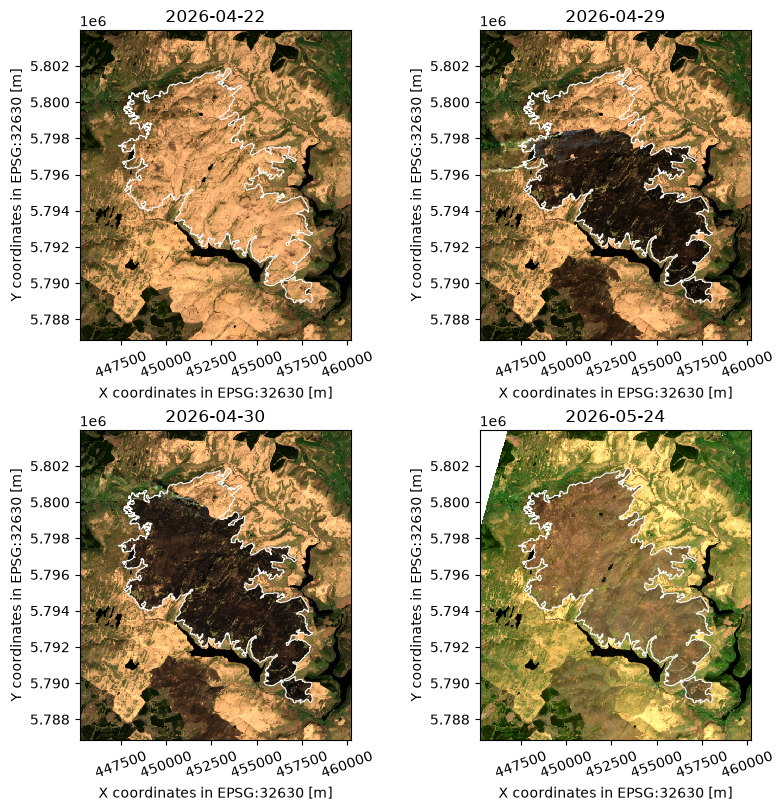

In [22]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 8), layout="constrained")

for ax, t in zip(axes.flat, scenes["time"].values):

    scenes.sel(time=t, band=["red", "green", "blue"]).plot.imshow(ax=ax, robust=True)
    fire_gdf.boundary.plot(ax=ax, color="white", linewidth=0.8)
    ax.set_title(str(t)[:10])
    ax.set_aspect("equal")

    ax.set_xlabel("X coordinates in EPSG:32630 [m]")
    ax.set_ylabel("Y coordinates in EPSG:32630 [m]")
    ax.tick_params(axis="x", rotation=20)

    # ax.set_axis_off()

fig.savefig(figures_dir / "fig1_rgb_timeseries.png", dpi=300)
plt.show()

## Figure 2: NBR

NBR for each date.

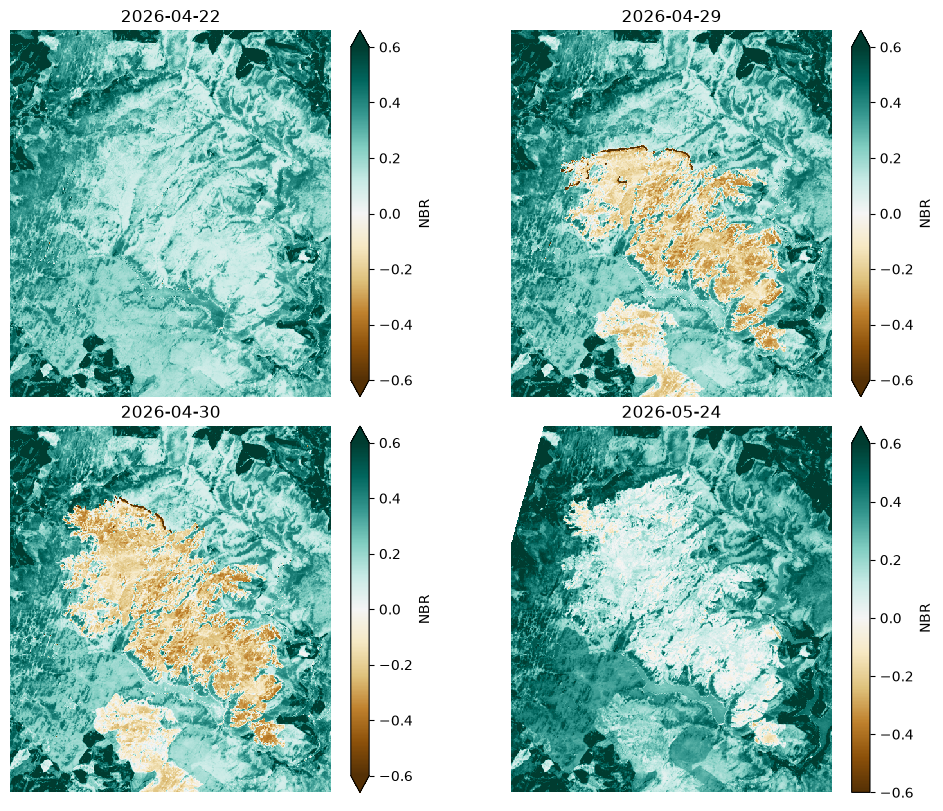

In [23]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), layout="constrained")

for ax, t in zip(axes.flat, nbr["time"].values):
    nbr.sel(time=t).plot.imshow(
        ax=ax, cmap="BrBG", vmin=-0.6, vmax=0.6, cbar_kwargs={"label": "NBR"}
    )
    ax.set_title(str(t)[:10])
    ax.set_aspect("equal")
    ax.set_axis_off()

fig.savefig(figures_dir / "fig2_nbr_timeseries.png", dpi=300)
plt.show()

## Figure 3: dNBR

dNBR relative to the pre-fire image (22 April), with the EFFIS fire perimeter outlined.

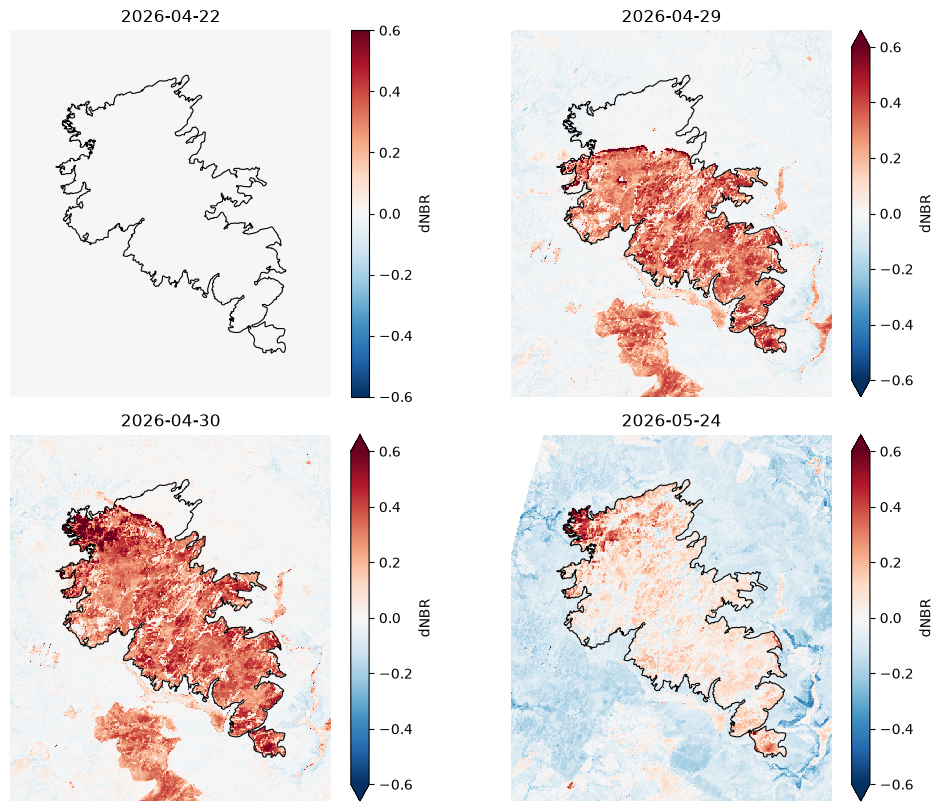

In [25]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), layout="constrained")

for ax, t in zip(axes.flat, dnbr["time"].values):
    dnbr.sel(time=t).plot.imshow(
        ax=ax, cmap="RdBu_r", vmin=-0.6, vmax=0.6, cbar_kwargs={"label": "dNBR"}
    )
    fire_gdf.boundary.plot(ax=ax, color="k", linewidth=0.8)
    ax.set_title(str(t)[:10])
    ax.set_aspect("equal")
    ax.set_axis_off()

fig.savefig(figures_dir / "fig3_dnbr_timeseries.png", dpi=300)
plt.show()

## Figure 4: Burned area through time

The area with dNBR > 0.27 on each date. The error bars show the range of areas given by thresholds of 0.26 and 0.28.

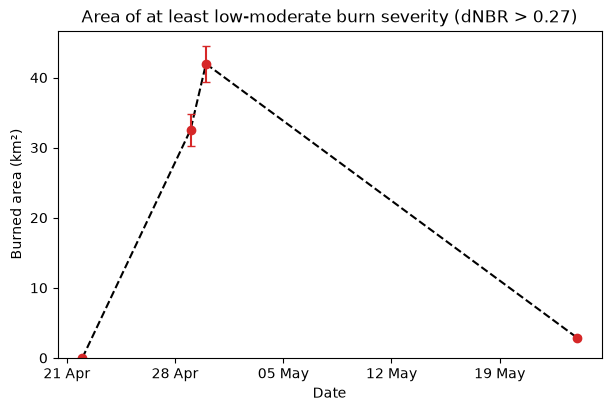

In [26]:
# Error bars are given as distances below and above each point
yerr = [
    df_area_burned["area_burned_km2"] - df_area_burned["area_burned_lower_km2"],
    df_area_burned["area_burned_upper_km2"] - df_area_burned["area_burned_km2"],
]

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

ax.plot(df_area_burned["date"], df_area_burned["area_burned_km2"], color="k", ls="--")
ax.errorbar(
    df_area_burned["date"], df_area_burned["area_burned_km2"],
    yerr=yerr, fmt="o", color="tab:red", capsize=3,
)

ax.set_ylim(0, None)
ax.set_xlabel("Date")
ax.set_ylabel("Burned area (km²)")
ax.set_title("Area of at least low-moderate burn severity (dNBR > 0.27)")

# Label the x-axis weekly, in the format "28 Apr"
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

fig.savefig(figures_dir / "fig4_burned_area.png", dpi=300)
plt.show()

The burned area increased from about 33 km² on 29 April to about 42 km² on 30 April, as the fire continued to spread to the north (this can also be seen in Figure 1). Varying the threshold by ±0.01 changes the area by around ±2.5 km², which is much smaller than the change between these two dates.

By 24 May, only about 3 km² still exceeds the threshold. This shows how quickly NBR recovers as the vegetation greens up, so dNBR thresholds should be applied to images taken soon after a fire.

Note that this area covers the whole AOI, so it includes the smaller burn scar to the south of the reservoir, which is outside the EFFIS perimeter.

## Figure 5: dNBR within the fire perimeter through time

The mean dNBR within the EFFIS fire perimeter on each date. The error bars show one standard deviation.

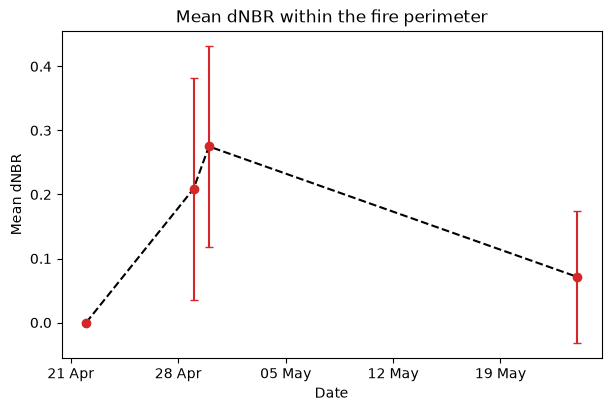

In [27]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

ax.plot(df_dnbr_stats["date"], df_dnbr_stats["dnbr_mean"], color="k", ls="--")
ax.errorbar(
    df_dnbr_stats["date"], df_dnbr_stats["dnbr_mean"],
    yerr=df_dnbr_stats["dnbr_std"], fmt="o", color="tab:red", capsize=3,
)

ax.set_xlabel("Date")
ax.set_ylabel("Mean dNBR")
ax.set_title("Mean dNBR within the fire perimeter")

ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

fig.savefig(figures_dir / "fig5_mean_dnbr.png", dpi=300)
plt.show()

## Figure 6: Variability in NBR

The standard deviation of NBR across all four dates. High values highlight the area that varied the most over the study period.

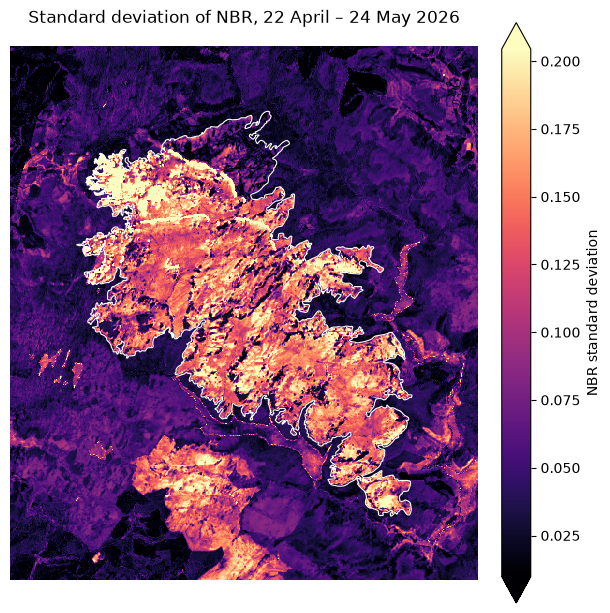

In [28]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")

nbr_std.plot.imshow(ax=ax, cmap="magma", robust=True, cbar_kwargs={"label": "NBR standard deviation"})
fire_gdf.boundary.plot(ax=ax, color="white", linewidth=0.8)
ax.set_title("Standard deviation of NBR, 22 April – 24 May 2026")
ax.set_aspect("equal")
ax.set_axis_off()

fig.savefig(figures_dir / "fig6_nbr_std.png", dpi=200)
plt.show()